In [2]:
!pip install tensorflow
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow Version:", tf.__version__)

  Using cached tensorflow-2.22.0rc0-cp314-cp314-win_amd64.whl.metadata (4.6 kB)
Using cached tensorflow-2.22.0rc0-cp314-cp314-win_amd64.whl (384.1 MB)
TensorFlow Version: 2.22.0-rc0


In [3]:
def build_sentiment_model(vocab_size=5000, max_len=100):
    model = Sequential([
        Embedding(input_dim=vocab_size, output_dim=64, input_length=max_len),
        SimpleRNN(64, return_sequences=False),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dense(3, activation='softmax') # 3 Classes: Positive, Neutral, Negative
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

sentiment_model = build_sentiment_model()
sentiment_model.summary()

C:\Users\SUJAL SAXENA\anaconda3\Lib\site-packages\keras\src\layers\core\embedding.py:117: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Sample social media texts for sentiment analysis
texts = [
    "I absolutely love this amazing product, highly recommended!",
    "Worst experience ever, totally disappointed with the service.",
    "It is okay, neither too good nor too bad.",
    "Outstanding performance and great design, very happy!",
    "Terrible quality, broke within a day of use.",
    "Average experience, nothing special to mention."
]

# Labels: 0 = Negative, 1 = Neutral, 2 = Positive
labels = np.array([2, 0, 1, 2, 0, 1])

# Tokenization
vocab_size = 5000
max_len = 20

tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(texts)

sequences = tokenizer.texts_to_sequences(texts)
padded_sequences = pad_sequences(sequences, maxlen=max_len, padding='post', truncating='post')

print("Padded Sequences Shape:", padded_sequences.shape)
print("Sample Padded Vector:", padded_sequences[0])

Padded Sequences Shape: (6, 20)
Sample Padded Vector: [ 4  5  6  7  8  9 10 11  0  0  0  0  0  0  0  0  0  0  0  0]


Epoch 1/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.1667 - loss: 1.0977  
Epoch 2/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.6667 - loss: 0.9958
Epoch 3/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 1.0000 - loss: 0.9044
Epoch 4/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 1.0000 - loss: 0.8886
Epoch 5/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 1.0000 - loss: 0.7213
Epoch 6/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 1.0000 - loss: 0.6188
Epoch 7/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 1.0000 - loss: 0.4653
Epoch 8/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 1.0000 - loss: 0.3810 
Epoch 9/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 1.0000 - loss: 0.3184
Epoch 10/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 1.0000 - loss: 0.2122


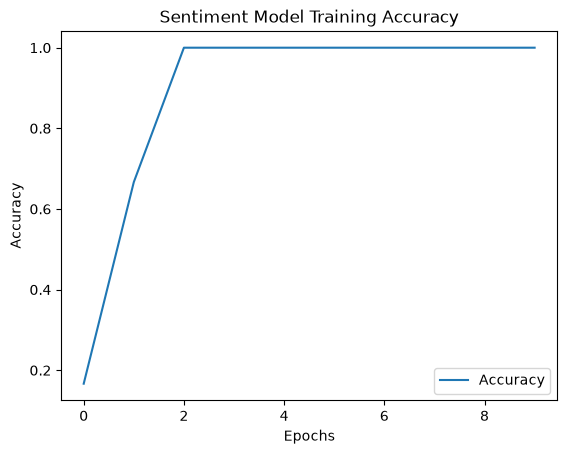

In [5]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np
import matplotlib.pyplot as plt

# 1. Dataset & Tokenization
texts = [
    "I absolutely love this amazing product, highly recommended!",
    "Worst experience ever, totally disappointed with the service.",
    "It is okay, neither too good nor too bad.",
    "Outstanding performance and great design, very happy!",
    "Terrible quality, broke within a day of use.",
    "Average experience, nothing special to mention."
]
labels = np.array([2, 0, 1, 2, 0, 1])

vocab_size = 5000
max_len = 20
tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(texts)
padded_sequences = pad_sequences(tokenizer.texts_to_sequences(texts), maxlen=max_len, padding='post', truncating='post')

# 2. Build Model
sentiment_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=64, input_length=max_len),
    SimpleRNN(64, return_sequences=False),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(3, activation='softmax')
])
sentiment_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# 3. Train Model
history = sentiment_model.fit(padded_sequences, labels, epochs=10, batch_size=2, verbose=1)

# 4. Plot
plt.plot(history.history['accuracy'], label='Accuracy')
plt.title('Sentiment Model Training Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()